# Analysis of model results

## Imports

In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.paths import RESULTS_DIR, PREPARED_FILES, PLOT_DIR
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif
from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'

## Configuration

In [3]:
az.rcParams["data.load"] = "eager"

## BFI analysis

In [4]:
msts_bfi_vehicle = pl.read_csv(PREPARED_FILES["bfi_vehicle"])
msts_bfi_empa = pl.read_csv(PREPARED_FILES["bfi_empa"])
msts_bfi_vehicle.describe()

statistic,,rat,gtyp,age,sex,vessel_idx,treatment,bfi_baseline,bfi_change,bfi_injected,log_bfi_baseline,log_bfi_injected,log_bfi_baseline_std,log_bfi_change
str,f64,str,str,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64
"""count""",763.0,"""763""","""763""","""763""","""763""",763.0,"""763""",763.0,763.0,763.0,763.0,763.0,763.0,763.0
"""null_count""",0.0,"""0""","""0""","""0""","""0""",0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",396.760157,null,null,null,null,12.087811,null,60.508247,3.396842,63.905089,4.082197,4.135394,-0.087787,0.053196
"""std""",225.030033,null,null,null,null,8.071947,null,12.346811,3.832176,13.554967,0.203315,0.209763,0.978514,0.059407
"""min""",15.0,"""20240813a""","""fa/+""","""Adult""","""F""",0.0,"""Vehicle""",29.043812,-7.538559,33.834568,3.368805,3.521483,-3.521196,-0.11578
"""25%""",205.0,null,null,null,null,5.0,null,50.708885,0.664391,53.904743,3.926101,3.987218,-0.839046,0.011429
"""50%""",385.0,null,null,null,null,11.0,null,59.074081,3.135319,61.920944,4.078792,4.125858,-0.104175,0.051714
"""75%""",589.0,null,null,null,null,18.0,null,68.218925,6.059395,72.643837,4.222722,4.285569,0.588529,0.098368
"""max""",825.0,"""20241030b""","""fa/fa""","""Young""","""M""",33.0,"""Vehicle""",102.490929,20.555809,109.41053,4.629774,4.695107,2.547588,0.251871


In [5]:
idata_empa = az.from_netcdf(RESULTS_DIR / "idata_bfi_empa.nc")
idata_vehicle = az.from_netcdf(RESULTS_DIR / "idata_bfi_vehicle.nc")
idata_bsl = az.from_netcdf(RESULTS_DIR / "idata_bfi_baseline_extra_interaction.nc")

In [6]:
print("Baseline (before Vehicle):")
display(az.summary(idata_bsl, var_names=["~mu", "~1|rat", "~sigma"]))
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))


Baseline (before Vehicle):


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,4.228,0.057,4.127,4.343,0.001,0.001,2059.0,1803.0,1.0
gtyp[fa/fa],-0.335,0.087,-0.505,-0.181,0.002,0.002,2208.0,2036.0,1.0
age[Young],-0.333,0.117,-0.560,-0.119,0.002,0.002,2687.0,2245.0,1.0
sex[M],-0.150,0.094,-0.334,0.018,0.002,0.002,2451.0,2267.0,1.0
"gtyp:age[fa/fa, Young]",0.375,0.153,0.079,0.652,0.003,0.003,2218.0,2098.0,1.0
"gtyp:sex[fa/fa, M]",0.399,0.137,0.158,0.670,0.003,0.003,2478.0,2754.0,1.0
"gtyp:age:sex[fa/+, Young, M]",0.350,0.156,0.051,0.636,0.003,0.003,2360.0,2374.0,1.0
"gtyp:age:sex[fa/fa, Young, M]",-0.002,0.149,-0.304,0.264,0.003,0.003,2798.0,2390.0,1.0
1|rat_sigma,0.147,0.022,0.109,0.190,0.001,0.001,1106.0,1865.0,1.0


Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.085,0.018,0.052,0.120,0.001,0.000,1088.0,1498.0,1.01
gtyp[fa/fa],-0.022,0.027,-0.070,0.031,0.001,0.001,1010.0,906.0,1.01
age[Young],0.033,0.028,-0.016,0.088,0.001,0.001,1312.0,1358.0,1.00
sex[M],-0.097,0.026,-0.145,-0.049,0.001,0.001,1213.0,1359.0,1.01
"gtyp:age[fa/fa, Young]",-0.031,0.036,-0.096,0.043,0.001,0.001,1217.0,1316.0,1.00
"gtyp:sex[fa/fa, M]",0.066,0.034,-0.001,0.128,0.001,0.001,1103.0,1497.0,1.00
1|rat_sigma,0.050,0.007,0.038,0.064,0.000,0.000,934.0,1482.0,1.01


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.159,0.021,-0.201,-0.119,0.001,0.001,879.0,956.0,1.01
gtyp[fa/fa],0.083,0.032,0.019,0.140,0.001,0.001,995.0,1202.0,1.00
age[Young],0.016,0.031,-0.038,0.078,0.001,0.001,1094.0,1241.0,1.00
sex[M],-0.032,0.029,-0.085,0.021,0.001,0.001,801.0,1037.0,1.00
"gtyp:age[fa/fa, Young]",-0.036,0.043,-0.116,0.051,0.001,0.001,1036.0,1324.0,1.00
"gtyp:sex[fa/fa, M]",0.021,0.042,-0.058,0.100,0.001,0.001,978.0,1152.0,1.00
1|rat_sigma,0.060,0.009,0.045,0.076,0.000,0.000,825.0,1241.0,1.00


In [7]:
msts_vehicle = pl.read_csv(PREPARED_FILES["bfi_vehicle"])
msts_empa = pl.read_csv(PREPARED_FILES["bfi_empa"])
msts_bsl = pl.read_csv(PREPARED_FILES["bfi"])

## Posterior predictive checks

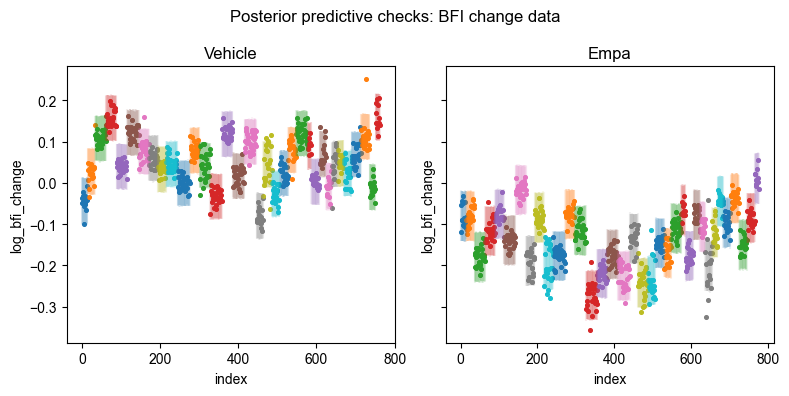

In [9]:
PLOT_DIR.mkdir(exist_ok=True)
f, axes = plt.subplots(1, 2, figsize=[8, 4], sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="log_bfi_change", groupcol="rat")
    ax.set_title(f"{name.capitalize()}");
    ax.get_legend().remove()

f.suptitle("Posterior predictive checks: BFI change data");
f.tight_layout()
f.savefig(PLOT_DIR / "ppc_bfi_change.png", bbox_inches="tight", dpi=200)

# Effects

In [10]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="TS (ln bfi change)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


In [11]:
t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))

overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups)
    for idata, t_groups in ((idata_vehicle, t_groups_vehicle), (idata_empa, t_groups_empa))
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

sex_ts_vehicle, sex_ts_empa = (get_sex_given_gtyp_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

# No interaction between sex and age, so remove sex given age
sex_ts_vehicle = {k:v for k,v in sex_ts_vehicle.items() if 'young' not in k and 'adult' not in k}
sex_ts_empa = {k:v for k,v in sex_ts_empa.items() if 'young' not in k and 'adult' not in k}

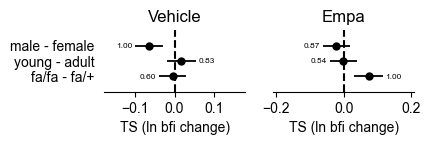

In [12]:
f, axes = plot_effects(overall_ts_vehicle, overall_ts_empa, figsize=(4, 0.8))
# f.tight_layout()
f.savefig(PLOT_DIR / "ts_bfi_change_overall.pdf", bbox_inches="tight", dpi=200)

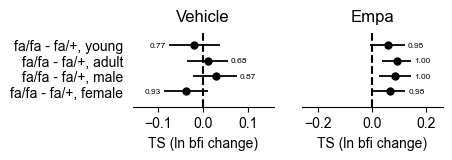

In [13]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR / "ts_bfi_change_gtyp_given_sex_age.pdf", bbox_inches="tight", dpi=200)

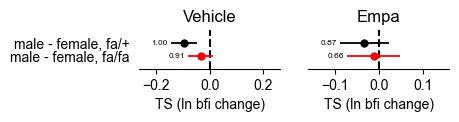

In [14]:
f, axes = plot_effects(sex_ts_vehicle, sex_ts_empa, figsize=(4, 0.5))
# f.tight_layout()
f.savefig(PLOT_DIR / "ts_bfi_change_sex_given_gtyp_age.pdf", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [15]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (overall_ts_vehicle, overall_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
            (sex_ts_vehicle, sex_ts_empa),        )
    ],
    keys=("overall", "gtyp given sex/age", "sex given age/gtyp"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif     empa  \
contrast           group                                                   
overall            fa/fa - fa/+          0.39550                 0.99875   
                   young - adult         0.83075                 0.45550   
                   male - female         0.00050              *  0.13375   
gtyp given sex/age fa/fa - fa/+, female  0.06975                 0.98400   
                   fa/fa - fa/+, male    0.87100                 0.99775   
                   fa/fa - fa/+, adult   0.68100                 0.99900   
                   fa/fa - fa/+, young   0.23425                 0.95475   
sex given age/gtyp male - female, fa/fa  0.09150                 0.34025   
                   male - female, fa/+   0.00050              *  0.12575   

                                        empa_signif  
contrast           group                             
overall            fa/fa - fa/+                   *  
                   young - adult                     
                   male - female                     
gtyp given sex/age fa/fa - fa/+, female           *  
                   fa/fa - fa/+, male             *  
                   fa/fa - fa/+, adult            *  
                   fa/fa - fa/+, young               
sex given age/gtyp male - female, fa/fa              
                   male - female, fa/+